In [2]:
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PCB = ROOT / "data/raw/DeepPCB/PCBData"


def read_split(name: str) -> list[dict]:
    """One row per pair listed in an official split file."""
    rows = []
    for line in (PCB / f"{name}.txt").read_text().splitlines():
        if not line.strip():
            continue
        img, ann = line.split()
        stem = img[:-4]
        rows.append({"split": name, "id": Path(stem).name,
                     "test_img": PCB / f"{stem}_test.jpg",
                     "ref_img": PCB / f"{stem}_temp.jpg",
                     "ann": PCB / ann})
    return rows


df = pd.DataFrame(read_split("trainval") + read_split("test"))
df["group"] = df["test_img"].apply(lambda p: p.parent.parent.name)
for col in ["test_img", "ref_img", "ann"]:
    df[col + "_ok"] = df[col].apply(Path.exists)

print(df["split"].value_counts().to_string())
print("missing files:", (~df[["test_img_ok", "ref_img_ok", "ann_ok"]]).sum().to_dict())
print("ids in both splits:", len(set(df.query("split == 'trainval'").id) & set(df.query("split == 'test'").id)))
print(pd.crosstab(df["group"], df["split"]).to_string())

split
trainval    1000
test         500
missing files: {'test_img_ok': 0, 'ref_img_ok': 0, 'ann_ok': 0}
ids in both splits: 0
split       test  trainval
group                     
group00041    21       200
group12000    14         0
group12100   146         0
group12300    98         0
group13000    18       198
group20085    34       291
group44000    50        50
group50600    29        50
group77000     7       100
group90100    74         0
group92000     9       111


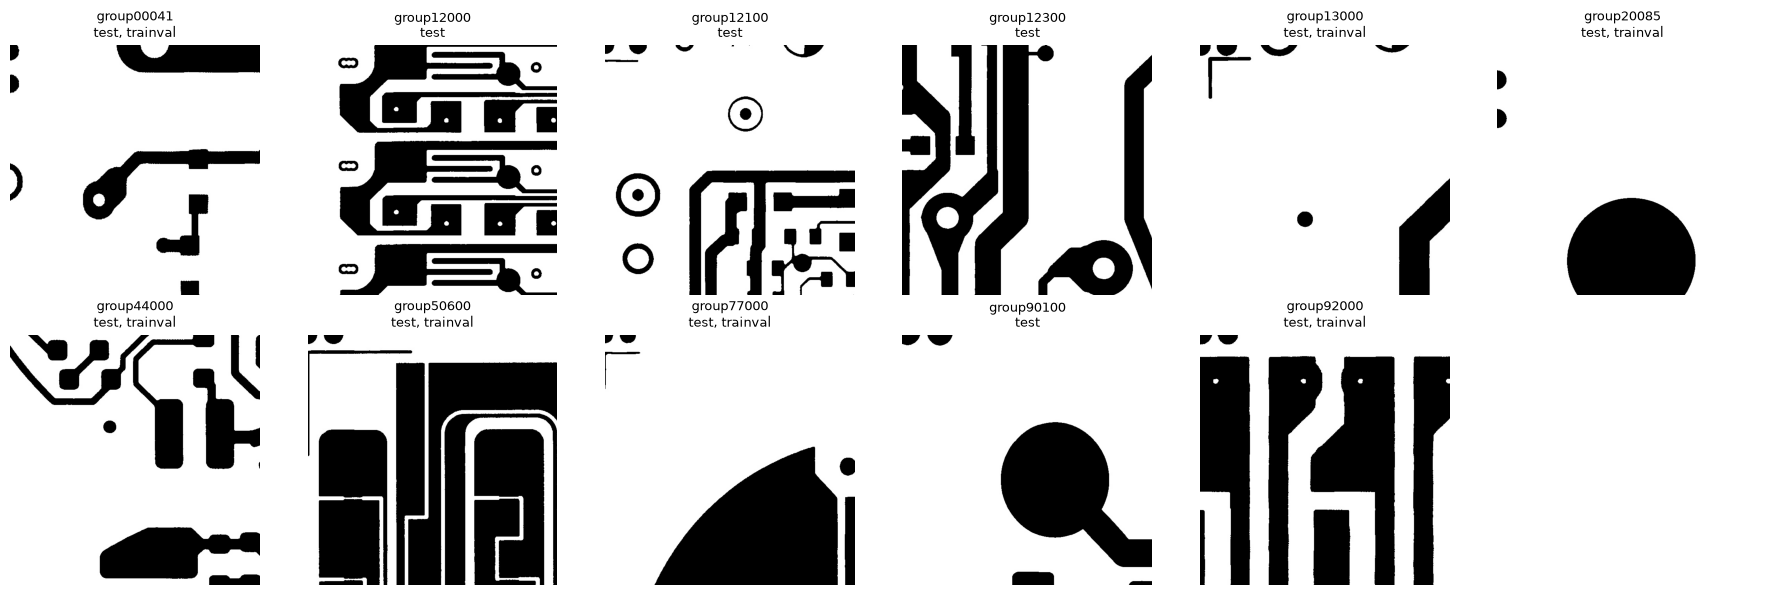

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

groups = sorted(df["group"].unique())
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, g in zip(axes.flat, groups):
    row = df[df["group"] == g].iloc[0]
    ax.imshow(Image.open(row["ref_img"]), cmap="gray")
    ax.set_title(f"{g}\n{', '.join(sorted(df[df['group'] == g]['split'].unique()))}", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(groups):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
records = []
for r in df.itertuples():
    for line in r.ann.read_text().splitlines():
        if line.strip():
            x1, y1, x2, y2, c = map(int, line.split())
            records.append({"id": r.id, "group": r.group, "split": r.split,
                            "cls": c, "w": x2 - x1, "h": y2 - y1})
boxes = pd.DataFrame(records)
boxes["cls_name"] = boxes["cls"].map({1: "open", 2: "short", 3: "mousebite",
                                      4: "spur", 5: "copper", 6: "pin-hole"})

print("total defects:", len(boxes))
print(pd.crosstab(boxes["group"], boxes["cls_name"], margins=True).to_string())
print()
print("defects per image:", boxes.groupby("id").size().describe().round(1).to_dict())
print("box width :", boxes["w"].describe().round(1).to_dict())
print("box height:", boxes["h"].describe().round(1).to_dict())

total defects: 10013
cls_name    copper  mousebite  open  pin-hole  short  spur    All
group                                                            
group00041     245        372   304       236    212   273   1642
group12000      14         11    23        11     19    15     93
group12100     143        177   178       145    131   145    919
group12300      89        112   137        96     80    86    600
group13000     255        328   211       254    141   262   1451
group20085     317        460   508       275    474   394   2428
group44000      99        147   160       110    120   111    747
group50600      57         72    85        76     70    72    432
group77000      90        107    89       113     76    83    558
group90100      70         76   109        73     88    67    483
group92000      95        103   138       112     95   117    660
All           1474       1965  1942      1501   1506  1625  10013

defects per image: {'count': 1500.0, 'mean': 6.7, 'std

In [5]:
splits_dir = ROOT / "data/processed/splits"
ids = {s: set(pd.read_csv(splits_dir / f"{s}.csv", dtype={"id": str})["id"]) for s in ["train", "val", "test"]}
boxes["our_split"] = boxes["id"].map({i: s for s, v in ids.items() for i in v})
print(pd.crosstab(boxes["our_split"], boxes["cls_name"], margins=True).to_string())

cls_name   copper  mousebite  open  pin-hole  short  spur    All
our_split                                                       
test          464        586   659       470    478   483   3140
train         841       1157  1059       816    852   963   5688
val           169        222   224       215    176   179   1185
All          1474       1965  1942      1501   1506  1625  10013
